In [1]:
import numpy as np

import matplotlib.pyplot as plt

U_inf=1
nu=1.57e-5
Re=1000
h=0.01
n_max=10
error=1e-6
steps = int(n_max/h)
y_max = n_max*nu*np.sqrt(Re)/U_inf
y = np.linspace(0, y_max, steps +1)
n=y*U_inf/(nu*np.sqrt(Re))
# n=np.linespace(0, n_max, steps +1)

#f0, f1, f2 ,f3
def blasius(f3_guess):
    Y1 = np.zeros(steps + 1)  
    Y2 = np.zeros(steps + 1)  # ise [] empty bhi likh sakte hai likn baad me .append() lagana padega
    Y3 = np.zeros(steps + 1)
    Y4 = np.zeros(steps + 1)

    Y1[0] = 0.0
    Y2[0] = 0.0
    Y3[0] = f3_guess # Y0, Y1, Y2, Y3;  

    for i in range (steps):
        f1 = Y1[i]
        f2 = Y2[i]  
        f3 = Y3[i]
        
        k1=f2  
        l1=f3
        m1= - f1*f3/2

        k2=f2+(h/2)*l1
        l2=f3+(h/2)*m1
        m2= - (f1*f3 +(h/2)*m1*f1 +(h/2)*k1*f3 +(h**2/4)*k1*m1)/2

        k3=f2+(h/2)*l2
        l3=f3+(h/2)*m2
        m3= - (f1*f3 +(h/2)*m2*f1 +(h/2)*k2*f3 +(h**2/4)*k2*m2)/2

        k4=f2+h*l3
        l4=f3+h*m3
        m4= - (f1*f3+h*m3*f1 +h*k3*f3 +(h**2)*k3*m3)/2

        Y1[i + 1] = f1 + (h / 6) * (k1 + 2 * k2 + 2 * k3 + k4)
        
        Y2[i + 1] = f2 + (h/6)*(l1+ 2*l2+2*l3+l4)
        
        Y3[i + 1]=f3 + (h/6)*(m1+ 2*m2+2*m3+m4)

    return Y1, Y2, Y3

def residual(f3_guess):
    _, Y2, _ = blasius(f3_guess)
    return Y2[-1] - 1.0 #f'(inf)=1

g1=0.1
g2=0.9


H1 = residual(g1)
H2 = residual(g2)

for it in range(100):
    g3 = g2 - H2 * (g2 - g1) / (H2 - H1)
    H3 = residual(g3)

    if abs(H3) < error:
        break

    g1 = g2
    H1 =  H2
    g2 = g3 
    H2 =  H3

Y1, Y2, Y3 = blasius(g3)
print(Y2[500])
print(Y3[0])

0.9915419012728148
0.33205733675387294


U, v vs y plot for different Re

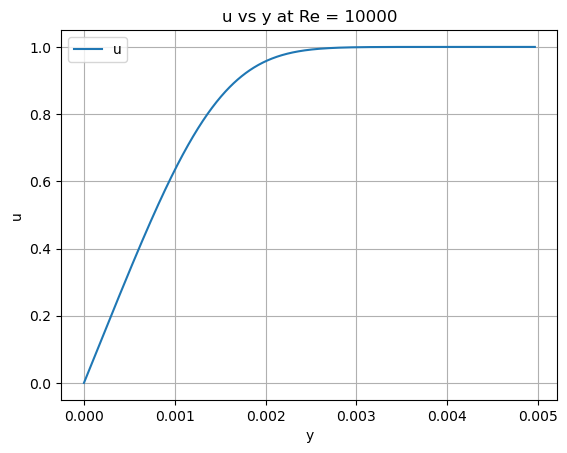

[-0.13090584 -0.13074773 -0.13058961 ...  0.02689181  0.02704993
  0.02720804]


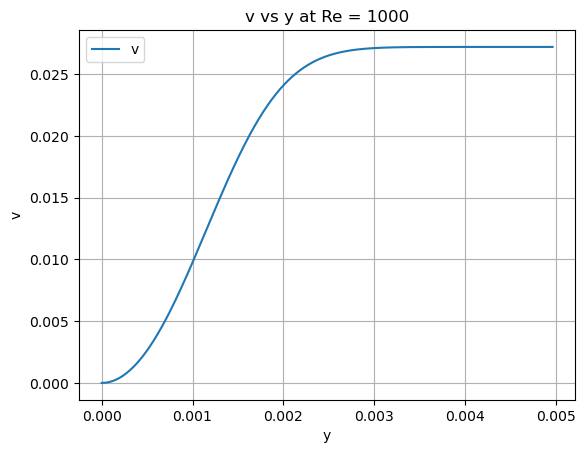

In [3]:
u = U_inf * Y2          

plt.plot(y, u, label="u")
plt.xlabel("y")
plt.ylabel("u")
plt.title("u vs y at Re = 10000")
plt.legend()
plt.grid(True)
plt.show()

v = (U_inf / (2*np.sqrt(Re))) * (n*Y2 - Y1)
v_edge=(U_inf / (2*np.sqrt(Re))) * (n*Y2[-1] - Y1[-1])
print(v_edge)
plt.plot(y, v, label="v")
plt.xlabel("y")
plt.ylabel("v")
plt.title("v vs y at Re = 1000")
plt.legend()
plt.grid(True)
plt.show()


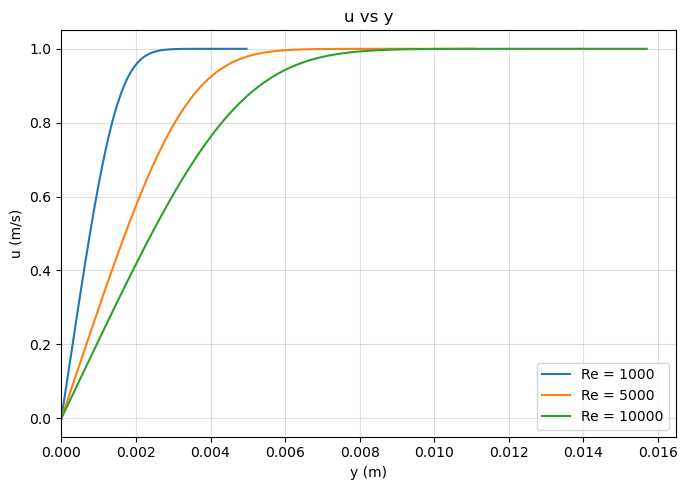

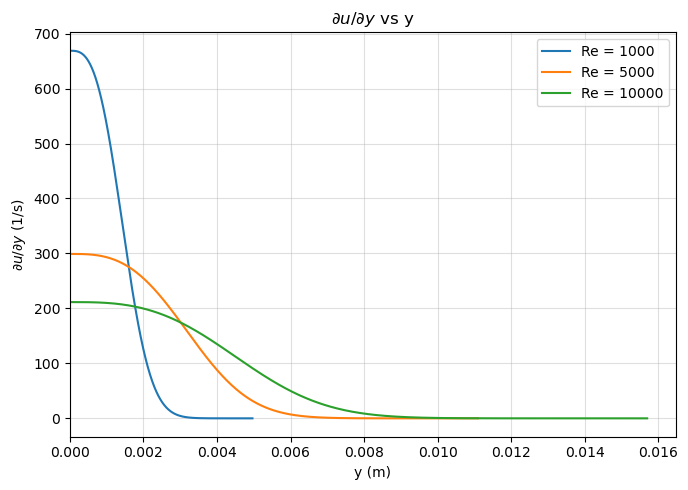

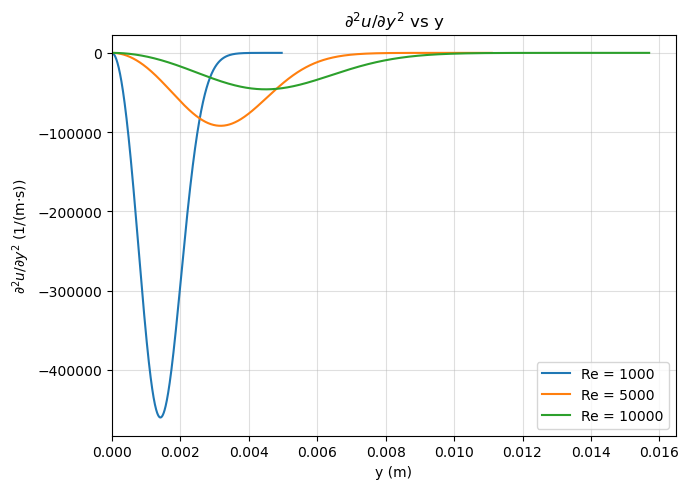

In [6]:

#f''' from the Blasius ODE itself (needed for d2u/dy2)
f3prime = -0.5 * Y1 * Y3

Re_list = [1000, 5000, 10000]
colors = ['tab:blue', 'tab:orange', 'tab:green']

# pre-compute y, u, dudy, d2udy2 for each Re once
profiles = {}
for Re in Re_list:
    c = U_inf / (nu * np.sqrt(Re))
    y = n / c
    u      = U_inf * Y2
    dudy   = U_inf * Y3 * c
    d2udy2 = U_inf * f3prime * c**2
    profiles[Re] = (y, u, dudy, d2udy2)

plt.figure(figsize=(7, 5))
for Re, color in zip(Re_list, colors):
    y, u, _, _ = profiles[Re]
    plt.plot(y, u, color=color, label=f"Re = {Re}")
plt.title("u vs y")
plt.xlabel("y (m)"); plt.ylabel("u (m/s)")
plt.grid(True, alpha=0.4)
plt.legend()
plt.xlim(0, None)
plt.tight_layout()
plt.show()


plt.figure(figsize=(7, 5))
for Re, color in zip(Re_list, colors):
    y, _, dudy, _ = profiles[Re]
    plt.plot(y, dudy, color=color, label=f"Re = {Re}")
plt.title(r"$\partial u/\partial y$ vs y")
plt.xlabel("y (m)"); plt.ylabel(r"$\partial u/\partial y$ (1/s)")
plt.grid(True, alpha=0.4)
plt.legend()
plt.xlim(0, None)
plt.tight_layout()
plt.show()


plt.figure(figsize=(7, 5))
for Re, color in zip(Re_list, colors):
    y, _, _, d2udy2 = profiles[Re]
    plt.plot(y, d2udy2, color=color, label=f"Re = {Re}")
plt.title(r"$\partial^2 u/\partial y^2$ vs y")
plt.xlabel("y (m)"); plt.ylabel(r"$\partial^2 u/\partial y^2$ (1/(m·s))")
plt.grid(True, alpha=0.4)
plt.legend()
plt.xlim(0, None)
plt.tight_layout()
plt.show()

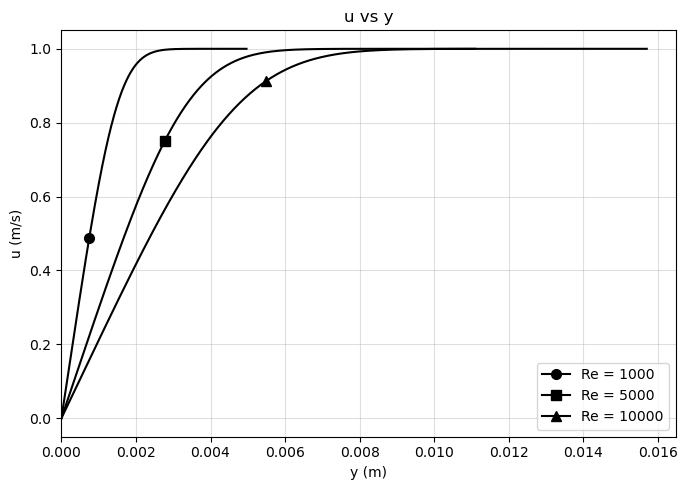

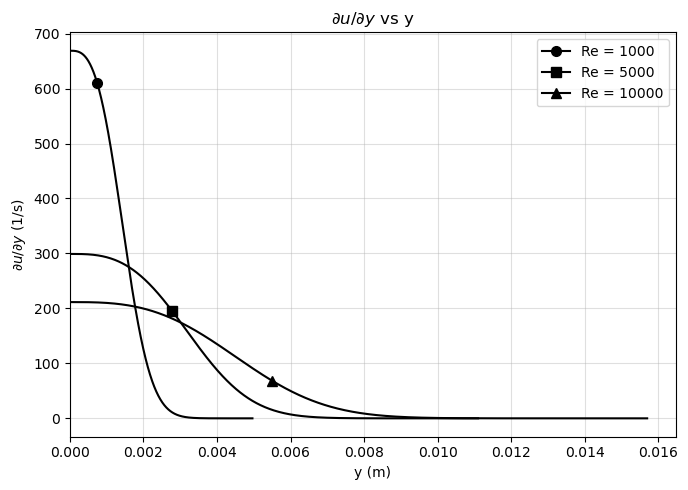

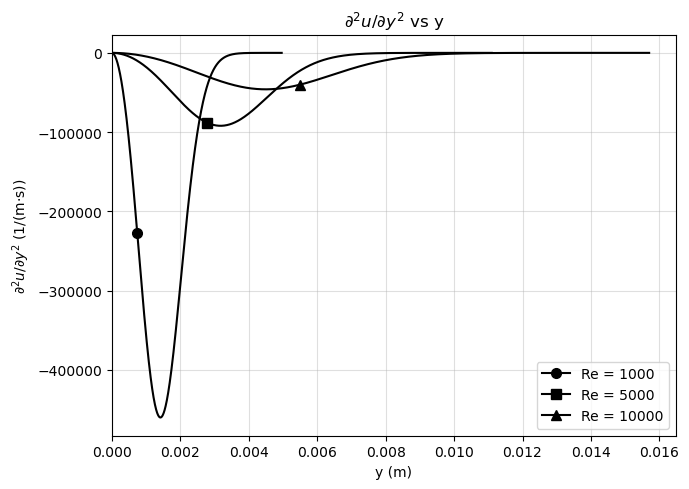

In [10]:
import matplotlib.pyplot as plt
import numpy as np

# f''' from the Blasius ODE itself (needed for d2u/dy2)
f3prime = -0.5 * Y1 * Y3

Re_list = [1000, 5000, 10000]
markers = ['o', 's', '^']  # Unique shapes for tracking

# Shift the single marker location for each Re so they don't overlap vertically
# Adjust these indices if your array 'n' is very small or very large
marker_positions = [[150], [250], [350]] 

# pre-compute y, u, dudy, d2udy2 for each Re once
profiles = {}
for Re in Re_list:
    c = U_inf / (nu * np.sqrt(Re))
    y = n / c
    u      = U_inf * Y2
    dudy   = U_inf * Y3 * c
    d2udy2 = U_inf * f3prime * c**2
    profiles[Re] = (y, u, dudy, d2udy2)

# ---- Plot 1: u vs y ----
plt.figure(figsize=(7, 5))
for Re, marker, pos in zip(Re_list, markers, marker_positions):
    y, u, _, _ = profiles[Re]
    # color='black' makes all lines identical, markevery=[idx] places exactly 1 marker
    plt.plot(y, u, color='black', marker=marker, markevery=pos, ms=7, label=f"Re = {Re}")
plt.title("u vs y")
plt.xlabel("y (m)"); plt.ylabel("u (m/s)")
plt.grid(True, alpha=0.4)
plt.legend()
plt.xlim(0, None)
plt.tight_layout()
plt.show()

# ---- Plot 2: du/dy vs y ----
plt.figure(figsize=(7, 5))
for Re, marker, pos in zip(Re_list, markers, marker_positions):
    y, _, dudy, _ = profiles[Re]
    plt.plot(y, dudy, color='black', marker=marker, markevery=pos, ms=7, label=f"Re = {Re}")
plt.title(r"$\partial u/\partial y$ vs y")
plt.xlabel("y (m)"); plt.ylabel(r"$\partial u/\partial y$ (1/s)")
plt.grid(True, alpha=0.4)
plt.legend()
plt.xlim(0, None)
plt.tight_layout()
plt.show()

# ---- Plot 3: d2u/dy2 vs y ----
plt.figure(figsize=(7, 5))
for Re, marker, pos in zip(Re_list, markers, marker_positions):
    y, _, _, d2udy2 = profiles[Re]
    plt.plot(y, d2udy2, color='black', marker=marker, markevery=pos, ms=7, label=f"Re = {Re}")
plt.title(r"$\partial^2 u/\partial y^2$ vs y")
plt.xlabel("y (m)"); plt.ylabel(r"$\partial^2 u/\partial y^2$ (1/(m·s))")
plt.grid(True, alpha=0.4)
plt.legend()
plt.xlim(0, None)
plt.tight_layout()
plt.show()


In [21]:
rho = 1.225   
mu = rho * nu
Re_list = [1000, 5000, 10000]
for Re in Re_list:
    x = Re * nu / U_inf

    c = U_inf / (nu * np.sqrt(Re))
    y = n / c
    u = U_inf * Y2

    derivative = np.gradient(u, y)  
    derivative_wall = derivative[0]       

    tau_w = mu * derivative_wall
    
    print(f"Re={Re}, x={x:.5f} m -> du/dy|wall = {derivative_wall:.5f} 1/s, tau_w = {tau_w:.6f} Pa")

Re=1000, x=0.01570 m -> du/dy|wall = 668.82643 1/s, tau_w = 0.012863 Pa
Re=5000, x=0.07850 m -> du/dy|wall = 299.10827 1/s, tau_w = 0.005753 Pa
Re=10000, x=0.15700 m -> du/dy|wall = 211.50149 1/s, tau_w = 0.004068 Pa


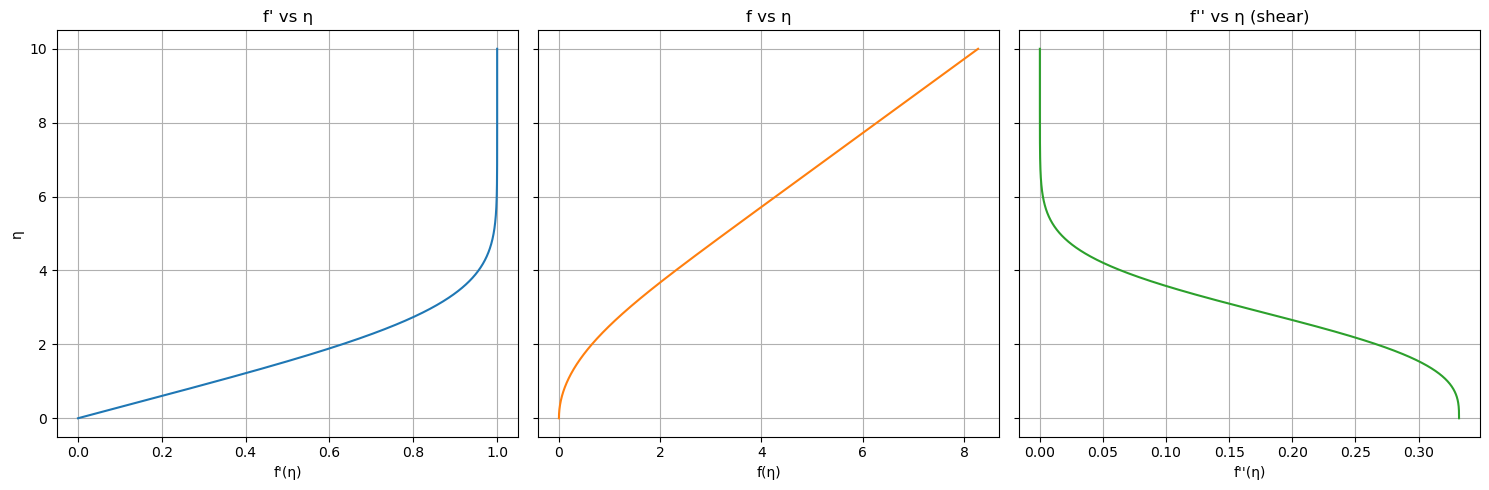

In [4]:

fig, axs = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

axs[0].plot(Y2, n, color='tab:blue')
axs[0].set_ylabel("η")
axs[0].set_xlabel("f'(η)")
axs[0].set_title("f' vs η")
axs[0].grid(True)

axs[1].plot(Y1, n, color='tab:orange')
axs[1].set_xlabel("f(η)")
axs[1].set_title("f vs η")
axs[1].grid(True)

axs[2].plot(Y3, n, color='tab:green')
axs[2].set_xlabel("f''(η)")
axs[2].set_title("f'' vs η (shear)")
axs[2].grid(True)

# axs[0].invert_yaxis()  

plt.tight_layout()
plt.show()

Fitted parameters [a, b, c]: [0.33216086 0.05331556 0.01456374]
R^2 = 0.9999996879183999


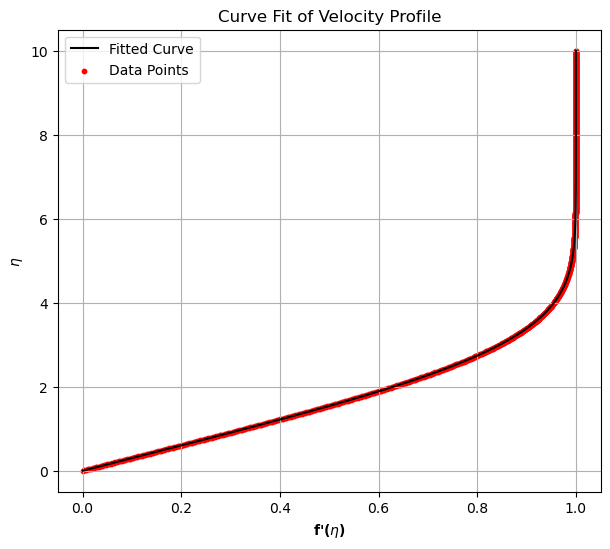

In [16]:
from scipy.optimize import curve_fit

eta = n
f_prime = Y2

def model_function(x, a, b,c ):
    return 1 - np.exp(-(a*x + b*x**2 + c*x**3 )) # + c*x**3 + d*x**4 + e*x**5

x_vals = eta
y_vals = f_prime

initial_guesses = [1.0, 0.5, 0.2 ]  #1, 0.5, 0.2, 0.1, 0.01
popt, pcov = curve_fit(model_function, x_vals, y_vals, bounds=(0, np.inf),
                        p0=initial_guesses, maxfev=500000)
y_fit = model_function(x_vals, *popt)

ss_res = np.sum((y_vals - y_fit) ** 2)
ss_tot = np.sum((y_vals - np.mean(y_vals)) ** 2)
r2 = 1 - (ss_res / ss_tot)

print("Fitted parameters [a, b, c]:", popt)
print("R^2 =", r2)

plt.figure(figsize=(7,6))
plt.plot(y_fit, x_vals, label="Fitted Curve", color='black', linewidth=1.5)
plt.scatter(y_vals, x_vals, color='red', s=10, label="Data Points")
plt.xlabel(r"f'($\eta$)", fontweight='bold')
plt.ylabel(r"$\eta$", fontweight='bold')
plt.title("Curve Fit of Velocity Profile")
plt.grid()
plt.legend()
plt.savefig('curve_fit_velocity_profile.png', dpi=300)
plt.show()

In [11]:
def model_function(x, a, b, c, d, e):
    return U_inf * (1 - np.exp(-(a*x + b*x**2 + c*x**3 + d*x**4 + e*x**5)))

Re_list = [1000, 5000, 10000]
initial_guesses = [300.0, 5000.0, 1e5, 1.0, 1.0]

for Re in Re_list:
    c_stretch = U_inf / (nu * np.sqrt(Re))
    y = n / c_stretch
    u = U_inf * Y2

    popt, pcov = curve_fit(model_function, y, u, bounds=(0, np.inf),
                            p0=initial_guesses, maxfev=500000)
    u_fit = model_function(y, *popt)

    ss_res = np.sum((u - u_fit)**2)
    ss_tot = np.sum((u - np.mean(u))**2)
    r2 = 1 - ss_res/ss_tot
    print(f"Re={Re}: R^2 = {r2:.9f}, params = {popt}")

NameError: name 'curve_fit' is not defined

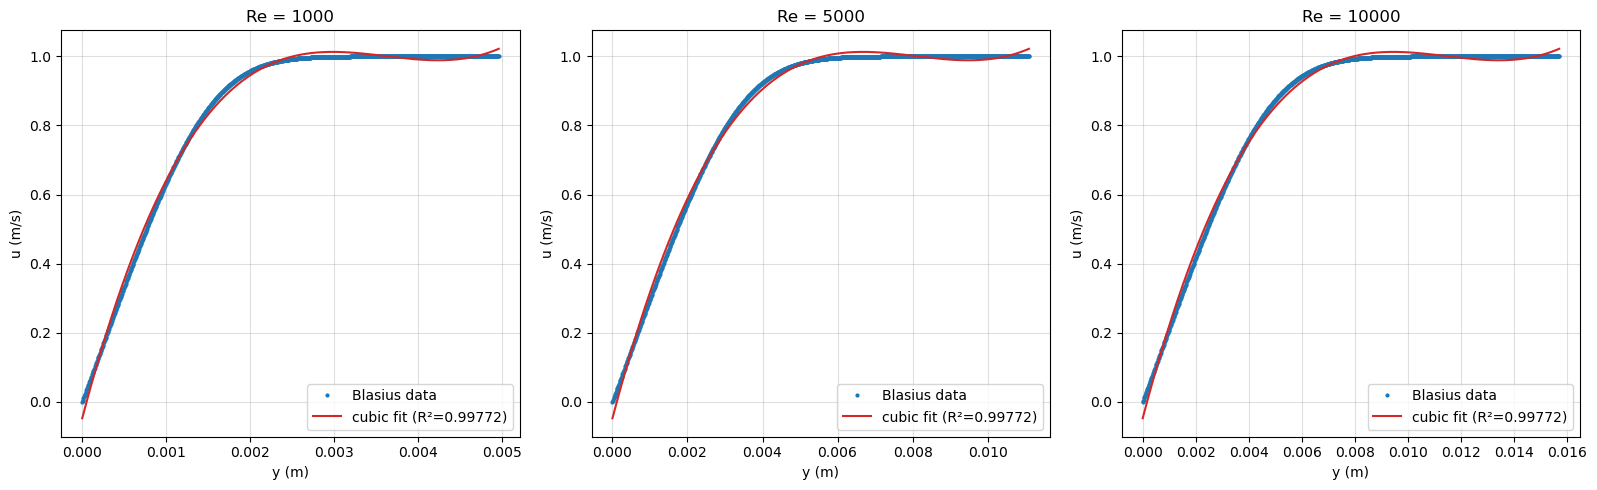

In [7]:
def r_squared(y_actual, y_fit):
    ss_res = np.sum((y_actual - y_fit)**2)
    ss_tot = np.sum((y_actual - np.mean(y_actual))**2)
    return 1 - ss_res/ss_tot

degree = 3

fig, axs = plt.subplots(1, 3, figsize=(16,5))
for ax, Re in zip(axs, Re_list):
    c = U_inf / (nu*np.sqrt(Re))
    y = n / c
    u = U_inf * Y2

    coeffs = np.polyfit(y, u, degree)
    u_fit = np.polyval(coeffs, y)
    R2 = r_squared(u, u_fit)

    ax.plot(y, u, 'o', ms=2, color='tab:blue', label='Blasius data')
    ax.plot(y, u_fit, '-', color='tab:red', label=f'cubic fit (R²={R2:.5f})')
    ax.set_title(f"Re = {Re}")
    ax.set_xlabel("y (m)"); ax.set_ylabel("u (m/s)")
    ax.grid(True, alpha=0.4)
    ax.legend()

plt.tight_layout()
plt.savefig('regression_fits.png', dpi=150)
plt.show()

In [15]:
x = np.argmax(Y2 >= 0.99)  
eta_99 = n[x]

print("Index where f' first reaches 0.99:", x)
print("eta_99 =", eta_99)
print("f'(eta_99) =", Y2[x])

Index where f' first reaches 0.99: 491
eta_99 = 4.91
f'(eta_99) = 0.9900001940958346


[-0.13090584 -0.13074773 -0.13058961 ...  0.02689181  0.02704993
  0.02720804]
[-0.05854287 -0.05847216 -0.05840145 ...  0.01202638  0.0120971
  0.01216781]
[-0.04139606 -0.04134606 -0.04129606 ...  0.00850394  0.00855394
  0.00860394]


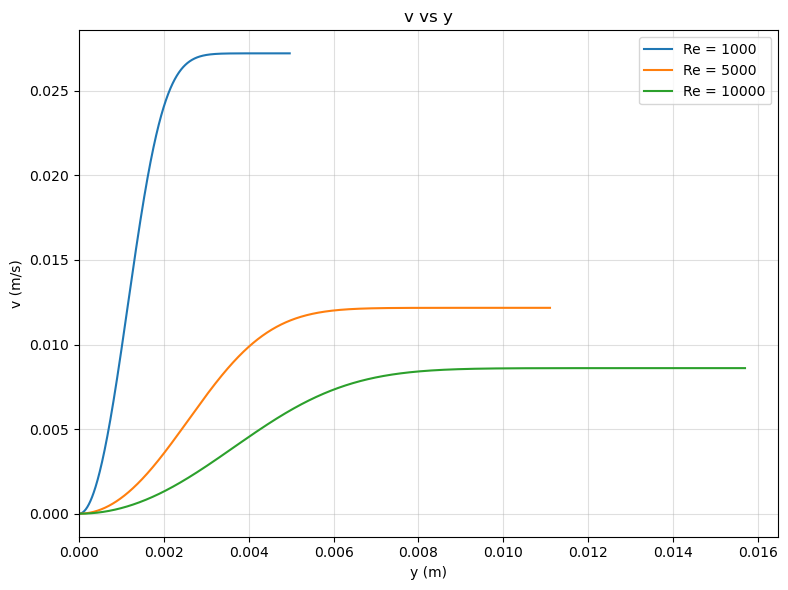

In [20]:
Re_list = [1000, 5000, 10000]
colors = ['tab:blue', 'tab:orange', 'tab:green']

plt.figure(figsize=(8, 6))
for Re, color in zip(Re_list, colors):
    c = U_inf / (nu * np.sqrt(Re))    # deta/dy stretching factor
    y = n / c                          # physical y for this Re

    v = (U_inf / (2*np.sqrt(Re))) * (n*Y2 - Y1)
    v_egde =(U_inf / (2*np.sqrt(Re))) * (n*Y2[-1] - Y1[-1])
    print(v_egde)
    plt.plot(y, v, color=color, label=f"Re = {Re}")

plt.xlabel("y (m)")
plt.ylabel("v (m/s)")
plt.title("v vs y")
plt.grid(True, alpha=0.4)
plt.legend()
plt.xlim(0, None)
plt.tight_layout()
plt.show()